# Runaway notices and landings: Montego Bay and Kingston

Notebook 06 found that in 1763–1808 about two-thirds of the people landed at Montego Bay
had embarked in the Bight of Biafra, against about a third of those landed at Kingston. But
where people landed is not where they lived. This notebook looks at people who lived and
worked in Jamaica: the men and women whose escapes were advertised in Jamaican newspapers.

The notices come from the dataset *Fugitives from Slavery in Jamaica* (Anthony W. Wood and
Billy G. Smith, from Douglas B. Chambers's transcriptions), published through Enslaved.org
under CC BY 4.0. The library reads it as a supplementary source. Four newspapers are
covered:

- the *Cornwall Chronicle*, published in Montego Bay, 1775–1795;
- the *Jamaica Mercury*, Kingston, 1779–1780;
- the *Royal Gazette*, Kingston, 1791–1792;
- the *Weekly Jamaica Courant*, Kingston, 1718–1754, earlier than the rest.

A notice names the person, often their sex and age, and often an African "country" or
nation: Igbo, Coromantee, Congo, Moco, Chamba. These are the terms enslavers used, not
necessarily what people called themselves. Enslaved.org assigns each term a place of
origin, and those assignments are used here as published.

Needs the full data and the Enslaved.org source:
`uv run voyages fetch && uv run voyages fetch -d enslaved && uv run voyages build`.

In [1]:
import math

import matplotlib.pyplot as plt
import pandas as pd

import voyages
from voyages import Voyages

v = Voyages()
runaways = v.sql(
    """
    SELECT DISTINCT
        p.person_id, p.person_name, p.sex, p.ethnonym, p.ethnonym_as_written,
        p.ethnonym_place_of_origin AS origin, s.source_title AS newspaper, e.event_year AS year
    FROM enslaved_people p
    JOIN enslaved_roles r ON r.person_id = p.person_id AND r.participant_role = 'Runaway'
    JOIN enslaved_events e ON e.event_id = r.event_id
    JOIN enslaved_record_sources rs ON rs.record_id = p.person_id
    JOIN enslaved_sources s ON s.source_id = rs.source_id
    JOIN enslaved_projects pr ON pr.project_id = s.project_id
    WHERE pr.project_code = 'FSJ' AND s.source_title NOT LIKE 'Chambers%'
    """
).to_pandas()
assert runaways.person_id.is_unique
len(runaways)

782

In [2]:
papers = runaways.groupby("newspaper").agg(
    people=("person_id", "size"),
    first=("year", "min"),
    last=("year", "max"),
    with_origin=("origin", "count"),
)
papers

,people,first,last,with_origin
newspaper,,,,
Cornwall Chronicle,452,1775,1795,269
Jamaica Mercury,142,1779,1780,79
Royal Gazette,112,1791,1792,73
Weekly Jamaica Courant,76,1718,1754,33


## Origins

The term as written in the notice, where Enslaved.org has no standard ethnonym for it, else
the standard ethnonym, with the place of origin Enslaved.org gives.

In [3]:
runaways["term"] = runaways.ethnonym_as_written.fillna(runaways.ethnonym)
terms = (
    runaways.dropna(subset=["origin"])
    .groupby(["origin", "term"])
    .size()
    .rename("people")
    .reset_index()
    .sort_values(["origin", "people"], ascending=[True, False])
)
terms

,origin,term,people
0,America,American,13
2,Bight of Benin,Popo,11
3,Bight of Benin,Yoruba,4
1,Bight of Benin,Nago,3
6,Bight of Biafra,Igbo,62
7,Bight of Biafra,Moco,31
5,Bight of Biafra,Eboe,4
4,Bight of Biafra,Calabar,2
9,Caribbean,Creole,118
8,Caribbean,Barbados,2


Most assignments follow common usage: Coromantee and Fante (and Chamba, people from the
interior who were sold through the Gold Coast forts) to the Gold Coast, Igbo, Eboe and Moco
to the Bight of Biafra, Popo and Nago to the Bight of Benin, Congo and Mungola to West
Central Africa, Mandingo and Canga to Upper Guinea. "Soso" (five people) is assigned to
West Central Africa; the name is more often read as the Susu of Upper Guinea, so it is a
small uncertainty.

To compare with the voyage data, both sides are put into the same groups. Enslaved.org's
"Greater Senegambia" covers what SlaveVoyages divides into Senegambia, Sierra Leone and the
Windward Coast; here it is "Upper Guinea", as in notebook 06. "Caribbean" and "America"
mean born in the Americas.

In [4]:
GROUPS = ["Bight of Biafra", "Gold Coast", "West Central Africa", "Bight of Benin", "Upper Guinea"]
ORIGIN_GROUP = {
    "Bight of Biafra": "Bight of Biafra",
    "Gold Coast": "Gold Coast",
    "West Central Africa": "West Central Africa",
    "Bight of Benin": "Bight of Benin",
    "Greater Senegambia": "Upper Guinea",
    "South East Africa": "Southeast Africa",
    "Caribbean": "Born in the Americas",
    "America": "Born in the Americas",
}
SV_GROUP = {
    "Bight of Biafra and Gulf of Guinea islands": "Bight of Biafra",
    "Gold Coast": "Gold Coast",
    "West Central Africa and St. Helena": "West Central Africa",
    "Bight of Benin": "Bight of Benin",
    "Senegambia and offshore Atlantic": "Upper Guinea",
    "Sierra Leone": "Upper Guinea",
    "Windward Coast": "Upper Guinea",
    "Southeast Africa and Indian Ocean islands": "Southeast Africa",
}
SIDE = {
    "Cornwall Chronicle": "Montego Bay",
    "Jamaica Mercury": "Kingston",
    "Royal Gazette": "Kingston",
    "Weekly Jamaica Courant": "Kingston, 1718–1754",
}
runaways["group"] = runaways.origin.map(ORIGIN_GROUP)
runaways["side"] = runaways.newspaper.map(SIDE)
assert runaways.group.notna().sum() == runaways.origin.notna().sum()

by_side = pd.crosstab(runaways.group.fillna("Not given"), runaways.side)
by_side

side,Kingston,"Kingston, 1718–1754",Montego Bay
group,,,
Bight of Benin,3,2,13
Bight of Biafra,13,6,80
Born in the Americas,75,5,53
Gold Coast,16,12,41
Not given,102,43,183
Southeast Africa,0,2,0
Upper Guinea,23,1,37
West Central Africa,22,5,45


More of the Kingston runaways were born in Jamaica or elsewhere in the Americas: 75 of 254
in the two later Kingston papers against 53 of 452 in the Montego Bay paper. The rest of the
comparison is about the African-born whose origin is given.

In [5]:
SIDES = ["Kingston", "Montego Bay"]
african = runaways[runaways.group.isin(GROUPS) & runaways.side.isin(SIDES)]
runaway_counts = pd.crosstab(african.group, african.side).reindex(GROUPS).fillna(0).astype(int)
runaway_share = (runaway_counts / runaway_counts.sum() * 100).round(1)
runaway_counts.assign(**{f"{s} (%)": runaway_share[s] for s in SIDES})

side,Kingston,Montego Bay,Kingston (%),Montego Bay (%)
group,,,,
Bight of Biafra,13,80,16.9,37.0
Gold Coast,16,41,20.8,19.0
West Central Africa,22,45,28.6,20.8
Bight of Benin,3,13,3.9,6.0
Upper Guinea,23,37,29.9,17.1


## Landings at the two ports

People landed at Kingston and Montego Bay from 1763, when Montego Bay's recorded landings
begin, to 1795, the last notice in the *Cornwall Chronicle*: many people advertised as
runaways had arrived years before. Imputed people disembarked, as in notebook 06.

In [6]:
landings = (
    v.transatlantic.disembarked_in("Kingston", "Montego Bay")
    .between(1763, 1795)
    .to_pandas(["disembarkation_place_name", "embarkation_region_name", "disembarked_imputed"])
    .assign(group=lambda d: d.embarkation_region_name.map(SV_GROUP))
)
landed = (
    landings[landings.group.isin(GROUPS)]
    .pivot_table(
        index="group", columns="disembarkation_place_name", values="disembarked_imputed",
        aggfunc="sum",
    )
    .reindex(GROUPS)[SIDES]
    .fillna(0)
    .astype(int)
)  # fmt: skip
landed_share = (landed / landed.sum() * 100).round(1)
landed.assign(**{f"{s} (%)": landed_share[s] for s in SIDES})

disembarkation_place_name,Kingston,Montego Bay,Kingston (%),Montego Bay (%)
group,,,,
Bight of Biafra,45037,23130,27.7,67.4
Gold Coast,57056,6078,35.2,17.7
West Central Africa,25037,0,15.4,0.0
Bight of Benin,18006,1246,11.1,3.6
Upper Guinea,17164,3839,10.6,11.2


## Side by side

Shares of the African-born with a known region, for runaways and for people landed. The
runaway figures rest on a few hundred people, so each comes with a 95% interval (Wilson).

In [7]:
def wilson(k: int, n: int, z: float = 1.96) -> tuple[float, float]:
    """95% Wilson score interval for a proportion k/n, in per cent."""
    p = k / n
    centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * math.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return round((centre - half) * 100, 1), round((centre + half) * 100, 1)


rows = []
for side in SIDES:
    n = int(runaway_counts[side].sum())
    for group in GROUPS:
        k = int(runaway_counts.loc[group, side])
        low, high = wilson(k, n)
        rows.append(
            {
                "port": side,
                "region": group,
                "runaways": k,
                "runaways (%)": runaway_share.loc[group, side],
                "95% interval": f"{low}–{high}",
                "low": low,
                "high": high,
                "landed (%)": landed_share.loc[group, side],
            }
        )
compare = pd.DataFrame(rows)
compare.drop(columns=["low", "high"])

,port,region,runaways,runaways (%),95% interval,landed (%)
0,Kingston,Bight of Biafra,13,16.9,10.1–26.8,27.7
1,Kingston,Gold Coast,16,20.8,13.2–31.1,35.2
2,Kingston,West Central Africa,22,28.6,19.7–39.5,15.4
3,Kingston,Bight of Benin,3,3.9,1.3–10.8,11.1
4,Kingston,Upper Guinea,23,29.9,20.8–40.8,10.6
5,Montego Bay,Bight of Biafra,80,37.0,30.9–43.7,67.4
6,Montego Bay,Gold Coast,41,19.0,14.3–24.7,17.7
7,Montego Bay,West Central Africa,45,20.8,16.0–26.7,0.0
8,Montego Bay,Bight of Benin,13,6.0,3.6–10.0,3.6
9,Montego Bay,Upper Guinea,37,17.1,12.7–22.7,11.2


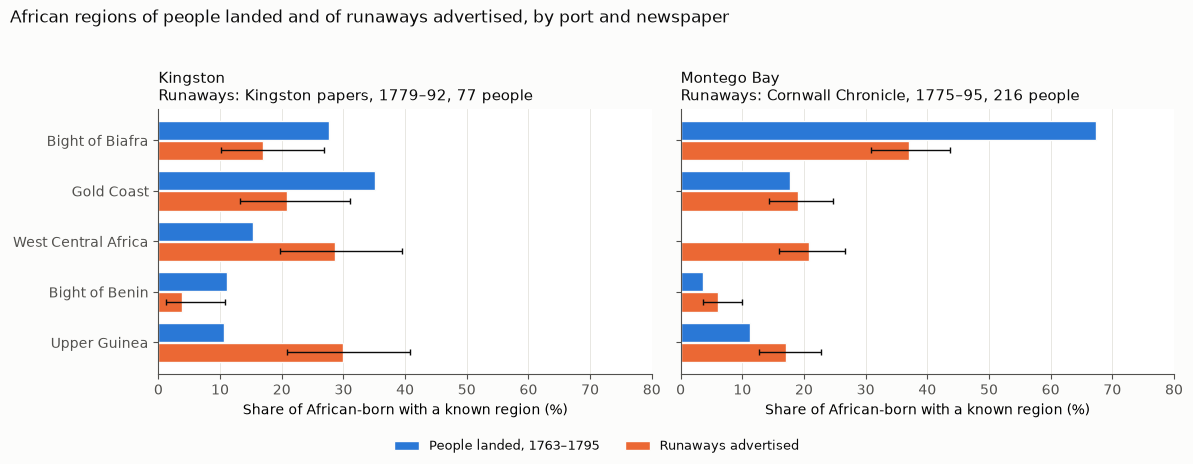

In [8]:
SURFACE, INK, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3dd"
LANDED, RAN = "#2a78d6", "#eb6834"
PAPERS = {"Kingston": "Kingston papers, 1779–92", "Montego Bay": "Cornwall Chronicle, 1775–95"}
plt.rcParams.update({"figure.facecolor": SURFACE, "text.color": INK, "font.size": 10})

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True)
for ax, side in zip(axes, SIDES, strict=True):
    c = compare[compare.port == side].set_index("region").loc[GROUPS]
    y = range(len(GROUPS))
    ax.barh(
        [i - 0.2 for i in y], c["landed (%)"], height=0.38, color=LANDED, edgecolor=SURFACE,
        linewidth=1, label="People landed, 1763–1795",
    )  # fmt: skip
    ax.barh(
        [i + 0.2 for i in y], c["runaways (%)"], height=0.38, color=RAN, edgecolor=SURFACE,
        linewidth=1, label="Runaways advertised",
    )  # fmt: skip
    ax.errorbar(
        c["runaways (%)"], [i + 0.2 for i in y],
        xerr=[c["runaways (%)"] - c.low, c.high - c["runaways (%)"]],
        fmt="none", ecolor=INK, elinewidth=1, capsize=2,
    )  # fmt: skip
    n_run = int(runaway_counts[side].sum())
    ax.set_title(
        f"{side}\nRunaways: {PAPERS[side]}, {n_run} people",
        loc="left", fontsize=10.5,
    )  # fmt: skip
    ax.set_yticks(list(y), GROUPS)
    ax.set_xlim(0, 80)
    ax.set_xlabel("Share of African-born with a known region (%)")
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color(MUTED)
    ax.tick_params(colors=MUTED)
    ax.xaxis.grid(True, color=GRID, linewidth=0.6)
    ax.set_axisbelow(True)
axes[0].invert_yaxis()  # shared y axis: invert once
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=2, frameon=False, fontsize=9)
fig.suptitle(
    "African regions of people landed and of runaways advertised, by port and newspaper",
    x=0.01, ha="left", fontsize=12,
)  # fmt: skip
fig.tight_layout(rect=(0, 0.06, 1, 0.95))
fig.savefig("figures/07_runaways_vs_landings.png", dpi=150)

What this shows:

- **The north-west difference shows up again.** Among the African-born runaways advertised
  in the Montego Bay paper, the Bight of Biafra is the largest group, 37%. In the Kingston
  papers it is 17%. The intervals do not overlap, and the direction is the same as in the
  landings (67% and 28%).
- **It is weaker than in the landings.** Biafrans were two-thirds of the people landed at
  Montego Bay but about a third of its runaways. A fifth of the Montego Bay runaways were
  from West Central Africa, although no one from there was landed at Montego Bay in these
  years: they had been bought elsewhere, most likely at Kingston, and taken to the
  north-west. So the landing port shows only part of who lived in a district.
- **Kingston's runaways do not mirror its landings either.** People from West Central
  Africa and Upper Guinea (Mandingo, Canga) are each about three in ten of its runaways,
  but 15% and 11% of the people landed there; the Gold Coast and the Bight of Biafra are
  under-represented. Runaways are not a random sample of the enslaved population: who
  escaped, and whose escape an enslaver paid to advertise, differed, and the Kingston
  papers carried notices from across the island.

## Caveats

- **Small numbers.** 216 African-born runaways with a region in the Montego Bay paper and
  77 in the Kingston papers.
- **Different years.** The Kingston papers cover two short spans (1779–1780 and 1791–1792);
  the Montego Bay paper covers twenty years.
- **Origins are enslavers' terms**, matched to regions by Enslaved.org. Some terms (Chamba,
  Moco) named broad inland groups rather than a coast.
- **A newspaper is not a parish.** The *Cornwall Chronicle* carried notices from across the
  western parishes, and Kingston papers took notices from the whole island.

## Checks

The figures quoted above, checked against the tables.

In [9]:
assert len(runaways) == 782
assert papers.people.to_dict() == {
    "Cornwall Chronicle": 452,
    "Jamaica Mercury": 142,
    "Royal Gazette": 112,
    "Weekly Jamaica Courant": 76,
}
assert (papers.loc["Cornwall Chronicle", "first"], papers.loc["Cornwall Chronicle", "last"]) == (
    1775,
    1795,
)
assert by_side.loc["Born in the Americas", ["Kingston", "Montego Bay"]].tolist() == [75, 53]
assert terms.set_index("term").loc["Soso", "origin"] == "West Central Africa"
assert runaway_counts.sum().tolist() == [77, 216]
mb = compare.set_index(["port", "region"])
biafra_mb = mb.loc[("Montego Bay", "Bight of Biafra")]
biafra_k = mb.loc[("Kingston", "Bight of Biafra")]
assert runaway_counts["Montego Bay"].idxmax() == "Bight of Biafra"
assert (biafra_mb["runaways (%)"], biafra_k["runaways (%)"]) == (37.0, 16.9)
assert biafra_mb.low > biafra_k.high  # intervals do not overlap
assert (landed_share.loc["Bight of Biafra", SIDES].tolist()) == [27.7, 67.4]
wca_mb = mb.loc[("Montego Bay", "West Central Africa")]
assert landed.loc["West Central Africa", "Montego Bay"] == 0 and wca_mb["runaways (%)"] > 19
for group in ("West Central Africa", "Upper Guinea"):
    k = mb.loc[("Kingston", group)]
    assert 28 <= k["runaways (%)"] <= 31 and k["runaways (%)"] > 1.8 * k["landed (%)"], group
for group in ("Gold Coast", "Bight of Biafra"):
    k = mb.loc[("Kingston", group)]
    assert k["runaways (%)"] < k["landed (%)"], group

Data: SlaveVoyages (voyages) and Enslaved.org, dataset *Fugitives from Slavery in Jamaica*
(Wood and Smith, https://doi.org/10.25971/a7na-ky57, CC BY 4.0).

In [10]:
print(voyages.citation())
print(voyages.citation("enslaved"))

SlaveVoyages, Trans-Atlantic Slave Trade Database, https://www.slavevoyages.org (accessed October 20, 2026).
Hawthorne, Walter, Daryle Williams, and Dean Rehberger, dirs. Enslaved: Peoples of the Historical Slave Trade (Enslaved.org), Version 2. Michigan State University: Matrix Center for Digital Humanities & Social Sciences, 2024. https://enslaved.org/ (accessed October 20, 2026).
